# Card fraud detection

Fraud is about 0.17% of card transactions, so a model that flags nothing is 99.8% accurate and useless.
This notebook builds a fraud model the way a card issuer would need it:

1. **Clean and explore** the transactions.
2. **Split by time**, so the model is always tested on transactions that happen after the ones it learned from.
3. **Compare baselines**: always predicting the fraud rate, then logistic regression, then XGBoost.
4. **Choose an alert threshold by cost**, weighing the cost of reviewing an alert against the value of fraud that gets through.
5. **Explain the model** with SHAP values.
6. **Check for drift** between training and test data with the Population Stability Index.
7. **Save the model** and score new transactions with a batch script.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_curve, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from fraud.data import TARGET, load_transactions, time_split
from fraud.evaluate import alert_cost, best_threshold, psi
from fraud.features import add_features, feature_columns

SEED = 42
REVIEW_COST = 5.0  # assumed cost of one analyst reviewing one alert
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:,.4f}".format)

## 1. Load and clean

In [2]:
raw = load_transactions(ROOT / "data")
print(f"{len(raw):,} transactions, {raw[TARGET].sum():,} fraud ({raw[TARGET].mean():.3%})")
raw.head()

284,807 transactions, 492 fraud (0.173%)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


In [3]:
pd.Series({
    "missing values": int(raw.isna().sum().sum()),
    "exact duplicate rows": int(raw.duplicated().sum()),
    "duplicate rows labelled fraud": int(raw.loc[raw.duplicated(), TARGET].sum()),
}).to_frame("count")

,count
missing values,0
exact duplicate rows,1081
duplicate rows labelled fraud,19


Exact duplicates are the same card transaction recorded twice. Keeping them would let a copy of a test
transaction sit in the training data, which flatters the results, so they are removed.

In [4]:
df = raw.drop_duplicates().reset_index(drop=True)
print(f"{len(df):,} transactions after removing duplicates, {df[TARGET].sum()} fraud")

283,726 transactions after removing duplicates, 473 fraud


## 2. Explore

In [5]:
(df.groupby(TARGET)["Amount"].describe()[["count", "mean", "50%", "max"]]
   .astype({"count": int}).rename(index={0: "genuine", 1: "fraud"}))

,count,mean,50%,max
Class,,,,
genuine,283253,88.4136,22.0000,"25,691.1600"
fraud,473,123.8719,9.8200,"2,125.8700"


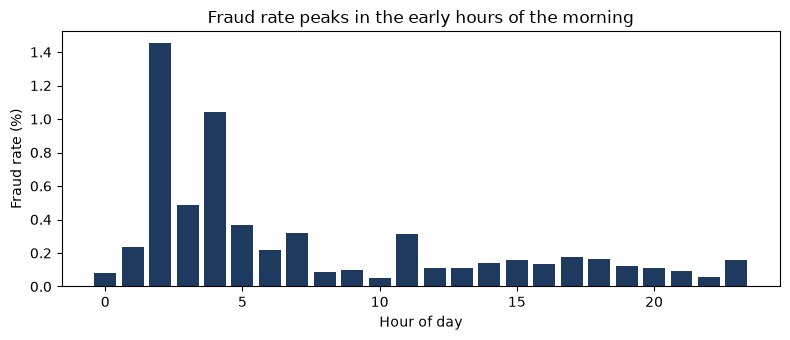

Fraud rate 00:00-05:59: 0.482%   06:00-23:59: 0.138%   ratio: 3.5x


In [6]:
feat = add_features(df)
by_hour = feat.groupby("hour")[TARGET].mean() * 100

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(by_hour.index, by_hour.values, color="#1f3a5f")
ax.set(xlabel="Hour of day", ylabel="Fraud rate (%)", title="Fraud rate peaks in the early hours of the morning")
fig.tight_layout()
fig.savefig(FIG_DIR / "fraud_rate_by_hour.png", dpi=150)
plt.show()

night, day = feat.loc[feat["hour"] < 6, TARGET].mean(), feat.loc[feat["hour"] >= 6, TARGET].mean()
print(f"Fraud rate 00:00-05:59: {night:.3%}   06:00-23:59: {day:.3%}   ratio: {night / day:.1f}x")

Genuine spending drops sharply overnight while fraud does not, so the fraud rate at night is several times the
daytime rate. That is the reason for the `is_night` feature.

## 3. Split by time

In [7]:
train, valid, test = time_split(feat, train_frac=0.6, valid_frac=0.2)
FEATURES = feature_columns(feat)

for name, part in [("train", train), ("valid", valid), ("test", test)]:
    print(f"{name:5s} {len(part):7,} rows  {part[TARGET].sum():3d} fraud  ({part[TARGET].mean():.3%})")

X_tr, y_tr = train[FEATURES], train[TARGET]
X_va, y_va = valid[FEATURES], valid[TARGET]
X_te, y_te = test[FEATURES], test[TARGET]

train 170,235 rows  342 fraud  (0.201%)
valid  56,745 rows   57 fraud  (0.100%)
test   56,746 rows   74 fraud  (0.130%)


## 4. Baselines and models

Accuracy is meaningless here, so models are compared on **PR-AUC** (average precision), which only rewards
finding fraud without raising false alerts. ROC-AUC is shown too, but it looks good even for weak fraud
models because genuine transactions vastly outnumber fraud.

In [8]:
results = {}

def record(name, scores):
    results[name] = {"PR-AUC": average_precision_score(y_te, scores), "ROC-AUC": roc_auc_score(y_te, scores)}

dummy = DummyClassifier(strategy="prior").fit(X_tr, y_tr)
record("Baseline: predict the fraud rate", dummy.predict_proba(X_te)[:, 1])

logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED),
).fit(X_tr, y_tr)
record("Logistic regression", logreg.predict_proba(X_te)[:, 1])

model = xgb.XGBClassifier(
    n_estimators=1000, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
    eval_metric="aucpr", early_stopping_rounds=50, random_state=SEED, n_jobs=-1,
)
model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
print("Trees kept after early stopping:", model.best_iteration + 1)
record("XGBoost", model.predict_proba(X_te)[:, 1])

pd.DataFrame(results).T

Trees kept after early stopping: 91


,PR-AUC,ROC-AUC
Baseline: predict the fraud rate,0.0013,0.5000
Logistic regression,0.7439,0.9830
XGBoost,0.7900,0.9833


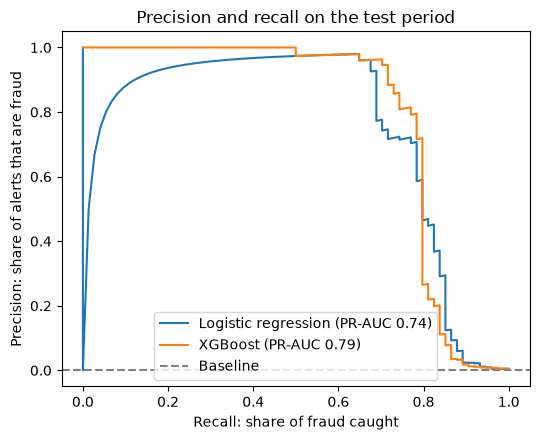

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for name, est in [("Logistic regression", logreg), ("XGBoost", model)]:
    precision, recall, _ = precision_recall_curve(y_te, est.predict_proba(X_te)[:, 1])
    ax.plot(recall, precision, label=f"{name} (PR-AUC {results[name]['PR-AUC']:.2f})")
ax.axhline(y_te.mean(), ls="--", c="grey", label="Baseline")
ax.set(xlabel="Recall: share of fraud caught", ylabel="Precision: share of alerts that are fraud",
       title="Precision and recall on the test period")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "precision_recall.png", dpi=150)
plt.show()

## 5. Choose the alert threshold by cost

Each alert costs a manual review, and each missed fraud costs its full amount. The threshold that minimises
the total is chosen on the **validation** period and then reported once on the **test** period.

In [10]:
va_scores = model.predict_proba(X_va)[:, 1]
te_scores = model.predict_proba(X_te)[:, 1]
threshold, _ = best_threshold(y_va, va_scores, valid["Amount"], REVIEW_COST)

alerts = te_scores >= threshold
tn, fp, fn, tp = confusion_matrix(y_te, alerts).ravel()
fraud_value = test.loc[y_te == 1, "Amount"].sum()
caught_value = test.loc[(y_te == 1) & alerts, "Amount"].sum()

pd.Series({
    "threshold (chosen on validation)": f"{threshold:.2f}",
    "alerts raised": f"{alerts.sum():,} of {len(test):,} transactions",
    "fraud caught": f"{tp} of {tp + fn} ({tp / (tp + fn):.0%})",
    "alerts that are fraud": f"{tp / max(tp + fp, 1):.0%}",
    "fraud value caught": f"{caught_value:,.0f} of {fraud_value:,.0f} ({caught_value / fraud_value:.0%})",
    "cost with no model": f"{fraud_value:,.0f}",
    "cost if every transaction is reviewed": f"{len(test) * REVIEW_COST:,.0f}",
    "cost with the model": f"{alert_cost(y_te, te_scores, test['Amount'], threshold, REVIEW_COST):,.0f}",
}).to_frame("test period")

,test period
threshold (chosen on validation),0.68
alerts raised,"52 of 56,746 transactions"
fraud caught,50 of 74 (68%)
alerts that are fraud,96%
fraud value caught,"3,998 of 7,728 (52%)"
cost with no model,"7,728"
cost if every transaction is reviewed,"283,730"
cost with the model,"3,989"


## 6. What drives the predictions

SHAP values split each prediction into one contribution per feature. XGBoost computes them natively with
`pred_contribs=True`. The chart shows the average size of each feature's contribution.

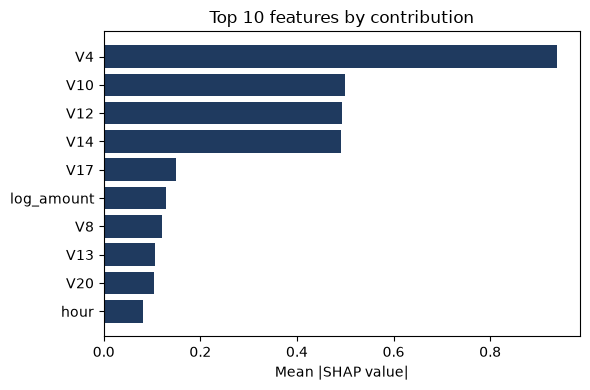

In [11]:
sample = X_te.sample(5000, random_state=SEED)
contribs = model.get_booster().predict(
    xgb.DMatrix(sample), pred_contribs=True, iteration_range=(0, model.best_iteration + 1)
)[:, :-1]  # the last column is the bias term
shap_importance = pd.Series(np.abs(contribs).mean(axis=0), index=FEATURES).sort_values(ascending=False)

top = shap_importance.head(10)[::-1]
fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(top.index, top.values, color="#1f3a5f")
ax.set(xlabel="Mean |SHAP value|", title="Top 10 features by contribution")
fig.tight_layout()
fig.savefig(FIG_DIR / "shap_importance.png", dpi=150)
plt.show()

In [12]:
# Sanity check: the top features should look clearly different for fraud and genuine transactions.
top3 = list(shap_importance.index[:3])
test.groupby(TARGET)[top3].mean().rename(index={0: "genuine", 1: "fraud"})

,V4,V10,V12
Class,,,
genuine,-0.1852,0.0079,0.1849
fraud,3.8943,-3.1281,-3.8913


## 7. Monitoring for drift

The Population Stability Index compares a feature's distribution in the training period with a later period.
Below 0.1 is stable, 0.1 to 0.25 is worth watching, and above 0.25 means the model should be reviewed.

In [13]:
train_scores = model.predict_proba(X_tr)[:, 1]
watch = list(dict.fromkeys(list(shap_importance.index[:5]) + ["log_amount", "hour"]))
drift = pd.DataFrame(
    {"PSI": [psi(train_scores, te_scores)] + [psi(X_tr[f], X_te[f]) for f in watch]},
    index=["model score"] + watch,
)
drift["status"] = pd.cut(drift["PSI"], [-np.inf, 0.1, 0.25, np.inf], labels=["stable", "watch", "review"])
drift

,PSI,status
model score,0.0633,stable
V4,0.1923,watch
V10,0.0474,stable
V12,0.2988,review
V14,0.1129,watch
V17,0.0547,stable
log_amount,0.0081,stable
hour,7.0464,review


**Reading the drift table.** The model score itself is stable, which is what matters most. The very high PSI
for `hour` is expected rather than alarming: the test period is the last few hours of day two, while training
covers whole days, so the mix of hours is different by design. In production, drift should be compared over
like-for-like windows, such as the same hours on different days. Features in the "review" band are the ones a
monitoring job would raise for a person to look at.

## 8. Save the model and score new transactions

In [14]:
model_dir = ROOT / "models"
model_dir.mkdir(exist_ok=True)
model.save_model(model_dir / "xgb_fraud.json")
(model_dir / "metadata.json").write_text(json.dumps(
    {"features": FEATURES, "threshold": threshold, "review_cost": REVIEW_COST,
     "trees": int(model.best_iteration + 1)}, indent=2))

425

The scoring script loads the saved model and threshold, so it should raise exactly the same alerts on the test
period as the notebook did.

In [15]:
test_path, scored_path = ROOT / "data" / "test_period.csv", ROOT / "data" / "test_period_scored.csv"
test[["Time", "Amount"] + [f"V{i}" for i in range(1, 29)]].to_csv(test_path, index=False)
run = subprocess.run([sys.executable, str(ROOT / "scripts" / "score.py"), str(test_path), str(scored_path)],
                     capture_output=True, text=True)
print(run.stdout or run.stderr)

scored = pd.read_csv(scored_path)
assert scored["alert"].sum() == alerts.sum(), "script and notebook disagree"
print("Script alerts match the notebook:", int(scored["alert"].sum()), "alerts")

Scored 56746 transactions: 52 alerts at threshold 0.68.

Script alerts match the notebook: 52 alerts
